# Proyek Analisis Data: Air Quality
- **Nama:** Ni Made Adelia Wirasanti
- **Email:** ds014b6x1372@student.devacademy.id
- **ID Dicoding:** DS014B6X1372

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan kualitas udara di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, dan stasiun mana yang memiliki rata-rata tertinggi?
- **Pertanyaan 2:** Bagaimana pola rata-rata konsentrasi PM2.5 berdasarkan bulan kalender pada 12 stasiun pemantauan di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, dan bulan apa yang memiliki rata-rata tertinggi?

## Import Semua Packages/Library yang Digunakan

In [17]:

# Import library untuk pengolahan dan analisis data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

#### Memuat dan Menggabungkan Dataset Air Quality



In [18]:

import os
import glob

# Mencari lokasi dataset sesuai lingkungan yang digunakan
if os.path.isdir("data"):
    data_path = "data"
elif os.path.isdir("/content/data"):
    data_path = "/content/data"
else:
    data_path = "/content"

# Mengambil seluruh file CSV Air Quality
csv_files = sorted(
    glob.glob(os.path.join(data_path, "PRSA_Data_*.csv"))
)

# Memastikan jumlah file sesuai
print("Lokasi dataset:", data_path)
print("Jumlah file CSV:", len(csv_files))

assert len(csv_files) == 12, (
    "Jumlah file CSV harus 12. "
    "Periksa lokasi dan kelengkapan dataset."
)

# Membaca seluruh file CSV
df_list = []

for file in csv_files:
    df = pd.read_csv(file)
    df_list.append(df)

# Menggabungkan seluruh dataset
air_quality_df = pd.concat(
    df_list,
    ignore_index=True
)

# Menampilkan informasi awal
print("Ukuran dataset:", air_quality_df.shape)

display(air_quality_df.head())


Lokasi dataset: /content
Jumlah file CSV: 12
Ukuran dataset: (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:** (Opsional)
- Dataset Air Quality terdiri dari 12 file CSV yang merepresentasikan pengukuran kualitas udara pada 12 stasiun pemantauan di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017.
- Seluruh file berhasil dimuat menggunakan pd.read_csv() dan digabungkan menggunakan pd.concat() sehingga menghasilkan DataFrame dengan 420.768 baris dan 18 kolom.
- Dataset memuat informasi waktu pengukuran, lokasi stasiun, konsentrasi polutan udara, serta kondisi meteorologi. Data selanjutnya akan diperiksa pada tahap Assessing Data sebelum digunakan untuk analisis.

### Assessing Data

#### Identifikasi Permasalahan Kualitas Data

In [19]:

# Memeriksa struktur dan informasi dataset
print("=== INFORMASI DATASET ===")
air_quality_df.info()

# Memeriksa jumlah missing value setiap kolom
print("\n=== MISSING VALUE ===")
missing_values = air_quality_df.isna().sum()
print(missing_values)

# Menghitung persentase missing value
print("\n=== PERSENTASE MISSING VALUE ===")
missing_percentage = (
    air_quality_df.isna().mean() * 100
).round(2)

print(missing_percentage)


=== INFORMASI DATASET ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

=== MISSING VALUE 

In [20]:

# Memeriksa jumlah baris yang identik
jumlah_duplikat = air_quality_df.duplicated().sum()

print("Jumlah baris duplikat:", jumlah_duplikat)

# Memeriksa duplikasi berdasarkan stasiun dan waktu
kolom_kunci = ["station", "year", "month", "day", "hour"]

duplikat_waktu = air_quality_df.duplicated(
    subset=kolom_kunci
).sum()

print("Jumlah duplikasi stasiun dan waktu:", duplikat_waktu)


Jumlah baris duplikat: 0
Jumlah duplikasi stasiun dan waktu: 0


In [21]:

# Memeriksa nilai negatif pada konsentrasi polutan
kolom_polutan = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

print("=== NILAI NEGATIF PADA POLUTAN ===")

for kolom in kolom_polutan:
    jumlah_negatif = (air_quality_df[kolom] < 0).sum()
    print(f"{kolom}: {jumlah_negatif} nilai negatif")

# Memeriksa nilai tidak valid pada waktu
print("\n=== VALIDASI WAKTU ===")

print("Bulan di luar 1-12:",
      (~air_quality_df["month"].between(1, 12)).sum())

print("Jam di luar 0-23:",
      (~air_quality_df["hour"].between(0, 23)).sum())

# Memeriksa nilai negatif pada kecepatan angin dan hujan
print("\n=== VALIDASI METEOROLOGI ===")

print("Kecepatan angin negatif:",
      (air_quality_df["WSPM"] < 0).sum())

print("Curah hujan negatif:",
      (air_quality_df["RAIN"] < 0).sum())


=== NILAI NEGATIF PADA POLUTAN ===
PM2.5: 0 nilai negatif
PM10: 0 nilai negatif
SO2: 0 nilai negatif
NO2: 0 nilai negatif
CO: 0 nilai negatif
O3: 0 nilai negatif

=== VALIDASI WAKTU ===
Bulan di luar 1-12: 0
Jam di luar 0-23: 0

=== VALIDASI METEOROLOGI ===
Kecepatan angin negatif: 0
Curah hujan negatif: 0


In [22]:

# Memeriksa statistik deskriptif PM2.5
print("=== STATISTIK DESKRIPTIF PM2.5 ===")
print(air_quality_df["PM2.5"].describe())

# Menghitung batas outlier menggunakan metode IQR
Q1 = air_quality_df["PM2.5"].quantile(0.25)
Q3 = air_quality_df["PM2.5"].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Mengidentifikasi nilai di luar batas IQR
outlier_pm25 = air_quality_df[
    (air_quality_df["PM2.5"] < batas_bawah) |
    (air_quality_df["PM2.5"] > batas_atas)
]

print("\n=== HASIL PEMERIKSAAN OUTLIER ===")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Jumlah potensi outlier:", len(outlier_pm25))


=== STATISTIK DESKRIPTIF PM2.5 ===
count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64

=== HASIL PEMERIKSAAN OUTLIER ===
Q1: 20.0
Q3: 111.0
IQR: 91.0
Batas bawah: -116.5
Batas atas: 247.5
Jumlah potensi outlier: 19142


**Steps to Take:**
- Menangani missing value pada dataset menggunakan metode yang sesuai dengan karakteristik masing-masing variabel. Untuk data pengukuran yang memiliki urutan waktu, penanganan akan mempertimbangkan stasiun pemantauan, urutan pengukuran, serta panjang rentang data yang hilang.
- Memeriksa lebih lanjut potensi outlier pada kolom PM2.5 yang teridentifikasi menggunakan metode IQR. Nilai ekstrem tidak akan langsung dihapus karena dapat merepresentasikan kondisi pencemaran udara yang sebenarnya.
- Mempertahankan data yang tidak memiliki masalah duplikasi dan nilai tidak valid berdasarkan pemeriksaan yang telah dilakukan.
- Melakukan pemeriksaan ulang setelah proses cleaning untuk memastikan hasil penanganan data sesuai dengan tujuan analisis.

**Insight:**
- Dataset Air Quality memiliki 420.768 baris dan 18 kolom, dengan beberapa kolom numerik dan kategoris yang mengandung missing value.
- Kolom CO memiliki missing value terbanyak, yaitu 20.701 data (4,92%), sedangkan kolom PM2.5 memiliki 8.739 missing value (2,08%). Missing value pada PM2.5 perlu mendapat perhatian khusus karena variabel tersebut digunakan untuk menjawab kedua pertanyaan bisnis.
- Tidak ditemukan duplikasi baris maupun duplikasi berdasarkan kombinasi stasiun dan waktu pengukuran.
- Tidak ditemukan nilai negatif pada konsentrasi polutan, curah hujan, dan kecepatan angin. Nilai bulan dan jam juga berada dalam rentang yang valid.
- Berdasarkan metode IQR, teridentifikasi 19.142 potensi outlier pada kolom PM2.5, dengan batas atas sebesar 247,5. Nilai tersebut akan diperiksa lebih lanjut dan tidak langsung dihapus karena kemungkinan merepresentasikan fenomena pencemaran udara yang nyata.

### Cleaning Data

#### Penanganan Missing Value dan Evaluasi Outlier

In [23]:

# Membuat salinan dataset sebelum proses cleaning
air_quality_clean_df = air_quality_df.copy()

# Memeriksa ukuran dataset
print("=== UKURAN DATASET ===")
print("Data asli:", air_quality_df.shape)
print("Data salinan:", air_quality_clean_df.shape)

# Menghitung missing value sebelum cleaning
print("\n=== MISSING VALUE SEBELUM CLEANING ===")
print(air_quality_clean_df.isna().sum())

# Memeriksa jumlah nilai PM2.5 yang hilang
print("\nMissing value PM2.5:",
      air_quality_clean_df["PM2.5"].isna().sum())


=== UKURAN DATASET ===
Data asli: (420768, 18)
Data salinan: (420768, 18)

=== MISSING VALUE SEBELUM CLEANING ===
No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64

Missing value PM2.5: 8739


In [24]:

# Mengurutkan data berdasarkan stasiun dan waktu
air_quality_clean_df = air_quality_clean_df.sort_values(
    by=["station", "year", "month", "day", "hour"]
).reset_index(drop=True)

# Menghitung missing value PM2.5 di setiap stasiun
missing_per_station = (
    air_quality_clean_df
    .groupby("station")["PM2.5"]
    .apply(lambda x: x.isna().sum())
    .sort_values(ascending=False)
)

print("=== MISSING VALUE PM2.5 PER STASIUN ===")
print(missing_per_station)

# Menampilkan total missing value PM2.5
print("\nTotal missing value PM2.5:",
      missing_per_station.sum())


=== MISSING VALUE PM2.5 PER STASIUN ===
station
Huairou          953
Aotizhongxin     925
Shunyi           913
Dingling         779
Changping        774
Dongsi           750
Wanshouxigong    696
Tiantan          677
Gucheng          646
Nongzhanguan     628
Guanyuan         616
Wanliu           382
Name: PM2.5, dtype: int64

Total missing value PM2.5: 8739


In [25]:

# Fungsi untuk menghitung rentetan missing value terpanjang
def longest_missing_streak(series):
    missing = series.isna()

    # Menandai setiap kelompok nilai berurutan
    group = missing.ne(missing.shift()).cumsum()

    # Menghitung panjang rentetan missing value
    streaks = missing.groupby(group).sum()

    return int(streaks.max()) if len(streaks) > 0 else 0


# Menghitung rentetan missing PM2.5 per stasiun
longest_streak = (
    air_quality_clean_df
    .groupby("station")["PM2.5"]
    .apply(longest_missing_streak)
    .sort_values(ascending=False)
)

print("=== RENTETAN MISSING VALUE PM2.5 TERPANJANG ===")
print(longest_streak)

print("\nRentetan terpanjang seluruh stasiun:",
      longest_streak.max(), "jam")


=== RENTETAN MISSING VALUE PM2.5 TERPANJANG ===
station
Aotizhongxin     343
Huairou          208
Shunyi           197
Changping        167
Dingling          72
Guanyuan          71
Dongsi            58
Nongzhanguan      56
Gucheng           54
Wanshouxigong     43
Tiantan           24
Wanliu            23
Name: PM2.5, dtype: int64

Rentetan terpanjang seluruh stasiun: 343 jam


In [26]:

# Memeriksa kontinuitas waktu setiap stasiun
data_waktu = air_quality_clean_df.copy()

# Membuat kolom datetime
data_waktu["datetime"] = pd.to_datetime(
    data_waktu[["year", "month", "day", "hour"]],
    errors="coerce"
)

# Mengurutkan data berdasarkan stasiun dan waktu
data_waktu = data_waktu.sort_values(
    by=["station", "datetime"]
)

# Menghitung selisih waktu antar pengamatan
selisih_waktu = (
    data_waktu.groupby("station")["datetime"]
    .diff()
    .dt.total_seconds() / 3600
)

# Menghitung interval yang tidak sama dengan 1 jam
interval_tidak_berurutan = (
    selisih_waktu.notna() &
    (selisih_waktu != 1)
).sum()

print("=== VALIDASI KONTINUITAS WAKTU ===")
print(
    "Jumlah waktu tidak valid:",
    data_waktu["datetime"].isna().sum()
)
print(
    "Jumlah interval tidak berurutan:",
    interval_tidak_berurutan
)
print(
    "Jumlah stasiun:",
    data_waktu["station"].nunique()
)


=== VALIDASI KONTINUITAS WAKTU ===
Jumlah waktu tidak valid: 0
Jumlah interval tidak berurutan: 0
Jumlah stasiun: 12


In [27]:

# Menghitung missing value sebelum interpolasi
missing_sebelum = air_quality_clean_df["PM2.5"].isna().sum()

# Fungsi interpolasi hanya untuk rentetan pendek (maksimal 3 jam)
def interpolasi_pendek(series):
    hasil = series.interpolate(
        method="linear",
        limit=3,
        limit_area="inside"
    )

    # Identifikasi panjang rentetan nilai kosong asli
    missing = series.isna()
    kelompok = missing.ne(missing.shift()).cumsum()
    panjang_rentetan = missing.groupby(kelompok).transform("sum")

    # Jangan isi rentetan yang lebih panjang dari 3 jam
    hasil[missing & (panjang_rentetan > 3)] = np.nan

    return hasil

# Interpolasi dilakukan terpisah per stasiun
air_quality_clean_df["PM2.5"] = (
    air_quality_clean_df
    .groupby("station")["PM2.5"]
    .transform(interpolasi_pendek)
)

# Memeriksa hasil interpolasi
missing_sesudah = air_quality_clean_df["PM2.5"].isna().sum()

print("=== HASIL INTERPOLASI PM2.5 ===")
print("Missing sebelum:", missing_sebelum)
print("Missing sesudah:", missing_sesudah)
print("Nilai berhasil diisi:", missing_sebelum - missing_sesudah)
print("Ukuran dataset:", air_quality_clean_df.shape)


=== HASIL INTERPOLASI PM2.5 ===
Missing sebelum: 8739
Missing sesudah: 5285
Nilai berhasil diisi: 3454
Ukuran dataset: (420768, 18)


In [28]:

# Mengidentifikasi data PM2.5 asli yang tidak kosong
data_asli_valid = air_quality_df["PM2.5"].notna()

# Membandingkan nilai asli dengan hasil cleaning
# Penyelarasan dilakukan berdasarkan stasiun dan waktu
kolom_kunci = ["station", "year", "month", "day", "hour"]

data_pembanding = air_quality_df[
    kolom_kunci + ["PM2.5"]
].merge(
    air_quality_clean_df[kolom_kunci + ["PM2.5"]],
    on=kolom_kunci,
    suffixes=("_asli", "_clean"),
    validate="one_to_one"
)

# Memeriksa perubahan pada nilai asli yang valid
nilai_berubah = (
    data_pembanding["PM2.5_asli"].notna() &
    (data_pembanding["PM2.5_asli"] != data_pembanding["PM2.5_clean"])
).sum()

# Memeriksa apakah interpolasi menghasilkan nilai negatif
nilai_negatif = (
    data_pembanding["PM2.5_clean"] < 0
).sum()

print("=== VALIDASI CLEANING PM2.5 ===")
print("Nilai asli yang berubah:", nilai_berubah)
print("Nilai negatif setelah cleaning:", nilai_negatif)
print("Missing value tersisa:",
      air_quality_clean_df["PM2.5"].isna().sum())
print("Ukuran dataset:",
      air_quality_clean_df.shape)


=== VALIDASI CLEANING PM2.5 ===
Nilai asli yang berubah: 0
Nilai negatif setelah cleaning: 0
Missing value tersisa: 5285
Ukuran dataset: (420768, 18)


**Insight:**
- Proses cleaning dilakukan pada salinan dataset (air_quality_clean_df) sehingga data asli tetap dipertahankan sebagai referensi.
- Penanganan missing value difokuskan pada kolom PM2.5 karena merupakan variabel utama yang digunakan untuk menjawab kedua pertanyaan bisnis.
- Berdasarkan validasi kontinuitas waktu, seluruh data pada 12 stasiun memiliki tanggal dan jam yang valid serta interval pengamatan berurutan setiap satu jam. Tidak ditemukan waktu yang tidak valid maupun interval yang terputus.
-Interpolasi linear dilakukan secara terpisah untuk setiap stasiun pemantauan dan hanya diterapkan pada rentetan missing value maksimal 3 jam yang memiliki pengukuran valid di kedua sisinya. Hal ini dilakukan agar estimasi tidak diterapkan pada rentetan data kosong yang terlalu panjang.
- Sebelum cleaning, terdapat 8.739 missing value pada kolom PM2.5. Setelah interpolasi, sebanyak 3.454 nilai berhasil diestimasi sehingga jumlah missing value berkurang menjadi 5.285.
- Missing value yang tersisa tetap dipertahankan karena tidak memenuhi kriteria interpolasi terbatas. Pada proses analisis selanjutnya, nilai kosong tersebut tidak disertakan dalam perhitungan rata-rata dengan tetap memperhatikan jumlah pengamatan valid pada setiap kelompok.
- Hasil validasi menunjukkan bahwa tidak ada nilai PM2.5 asli yang valid berubah, tidak ditemukan nilai negatif setelah interpolasi, dan ukuran dataset tetap sebanyak 420.768 baris dengan 18 kolom.
- Sebanyak 19.142 nilai PM2.5 sebelumnya teridentifikasi sebagai potensi outlier menggunakan metode IQR. Nilai tersebut tidak langsung dihapus atau diganti karena belum terdapat bukti bahwa nilai ekstrem tersebut merupakan kesalahan pengukuran dan mungkin mencerminkan kondisi pencemaran yang sebenarnya.
- Missing value pada variabel lain tetap dipertahankan karena variabel tersebut tidak digunakan dalam perhitungan utama untuk menjawab kedua pertanyaan bisnis.

## Exploratory Data Analysis (EDA)

### Analisis Konsentrasi PM2.5 Berdasarkan Stasiun dan Bulan

In [29]:

# Menghitung statistik PM2.5 berdasarkan stasiun
pm25_per_station = (
    air_quality_clean_df
    .groupby("station")["PM2.5"]
    .agg(["mean", "count", "min", "max"])
    .sort_values(by="mean", ascending=False)
)

# Mengganti nama kolom agar mudah dipahami
pm25_per_station = pm25_per_station.rename(
    columns={
        "mean": "Rata-rata PM2.5",
        "count": "Jumlah Data Valid",
        "min": "PM2.5 Minimum",
        "max": "PM2.5 Maksimum"
    }
)

# Menampilkan hasil analisis
print("=== STATISTIK PM2.5 BERDASARKAN STASIUN ===")
display(pm25_per_station.round(2))

# Menampilkan stasiun dengan rata-rata tertinggi dan terendah
print("\nStasiun dengan rata-rata PM2.5 tertinggi:",
      pm25_per_station.index[0])

print("Stasiun dengan rata-rata PM2.5 terendah:",
      pm25_per_station.index[-1])


=== STATISTIK PM2.5 BERDASARKAN STASIUN ===


,Rata-rata PM2.5,Jumlah Data Valid,PM2.5 Minimum,PM2.5 Maksimum
station,,,,
Dongsi,86.07,34586,3.0,737.0
Nongzhanguan,84.91,34767,2.0,844.0
Wanshouxigong,84.82,34651,3.0,999.0
Gucheng,83.79,34672,2.0,770.0
Wanliu,83.31,34898,2.0,957.0
Guanyuan,82.91,34698,2.0,680.0
Aotizhongxin,82.70,34408,3.0,898.0
Tiantan,81.98,34827,3.0,821.0
Shunyi,79.51,34475,2.0,941.0



Stasiun dengan rata-rata PM2.5 tertinggi: Dongsi
Stasiun dengan rata-rata PM2.5 terendah: Dingling


In [30]:

# Menghitung statistik PM2.5 berdasarkan bulan
pm25_per_month = (
    air_quality_clean_df
    .groupby("month")["PM2.5"]
    .agg(["mean", "count", "min", "max"])
    .sort_index()
)

# Mengganti nama kolom
pm25_per_month = pm25_per_month.rename(
    columns={
        "mean": "Rata-rata PM2.5",
        "count": "Jumlah Data Valid",
        "min": "PM2.5 Minimum",
        "max": "PM2.5 Maksimum"
    }
)

# Menampilkan hasil analisis
print("=== STATISTIK PM2.5 BERDASARKAN BULAN ===")
display(pm25_per_month.round(2))

# Menentukan bulan dengan rata-rata tertinggi dan terendah
bulan_tertinggi = pm25_per_month["Rata-rata PM2.5"].idxmax()
bulan_terendah = pm25_per_month["Rata-rata PM2.5"].idxmin()

print("\nBulan dengan rata-rata tertinggi:", bulan_tertinggi)
print("Bulan dengan rata-rata terendah:", bulan_terendah)


=== STATISTIK PM2.5 BERDASARKAN BULAN ===


,Rata-rata PM2.5,Jumlah Data Valid,PM2.5 Minimum,PM2.5 Maksimum
month,,,,
1,93.68,35513,2.0,835.0
2,87.51,32278,3.0,999.0
3,94.64,35546,3.0,558.0
4,72.83,34058,2.0,533.0
5,63.03,35057,3.0,844.0
6,68.98,33997,2.0,560.0
7,71.73,34940,3.0,540.0
8,53.40,35422,3.0,500.0
9,61.34,34046,3.0,477.0



Bulan dengan rata-rata tertinggi: 12
Bulan dengan rata-rata terendah: 8


**Insight:**
- Berdasarkan hasil analisis pada 12 stasiun pemantauan kualitas udara di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, stasiun Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi, yaitu 86,07 µg/m³, sedangkan stasiun Dingling memiliki rata-rata terendah, yaitu 66,00 µg/m³. Selisih rata-rata kedua stasiun mencapai 20,07 µg/m³. Hasil ini menunjukkan adanya variasi konsentrasi PM2.5 antarlokasi pemantauan.
- Berdasarkan pengelompokan data menurut bulan kalender, Desember memiliki rata-rata konsentrasi PM2.5 tertinggi, yaitu 104,29 µg/m³, sedangkan Agustus memiliki rata-rata terendah, yaitu 53,40 µg/m³. Selisih rata-rata kedua bulan mencapai 50,89 µg/m³. Perhitungan dilakukan dengan menggabungkan pengamatan pada bulan kalender yang sama dari beberapa tahun selama periode penelitian. Oleh karena itu, hasil ini menunjukkan pola perbedaan konsentrasi PM2.5 antarbulan, bukan tren perubahan secara kronologis dari tahun 2013 hingga 2017.
- Jumlah pengukuran valid pada setiap kelompok diperhitungkan menggunakan fungsi count(). Perhitungan rata-rata mengabaikan nilai PM2.5 yang masih kosong serta menyertakan nilai hasil interpolasi terbatas. Oleh karena itu, hasil analisis perlu diinterpretasikan dengan mempertimbangkan keterbatasan data dan estimasi yang digunakan.
- Hasil EDA memberikan dasar untuk menentukan prioritas evaluasi kualitas udara berdasarkan lokasi dan periode pemantauan. Namun, penyebab perbedaan konsentrasi PM2.5 belum dapat dipastikan hanya melalui analisis deskriptif ini.

## Visualization & Explanatory Analysis

### Pertanyaan 1:Perbandingan Rata-rata Konsentrasi PM2.5 Berdasarkan Stasiun

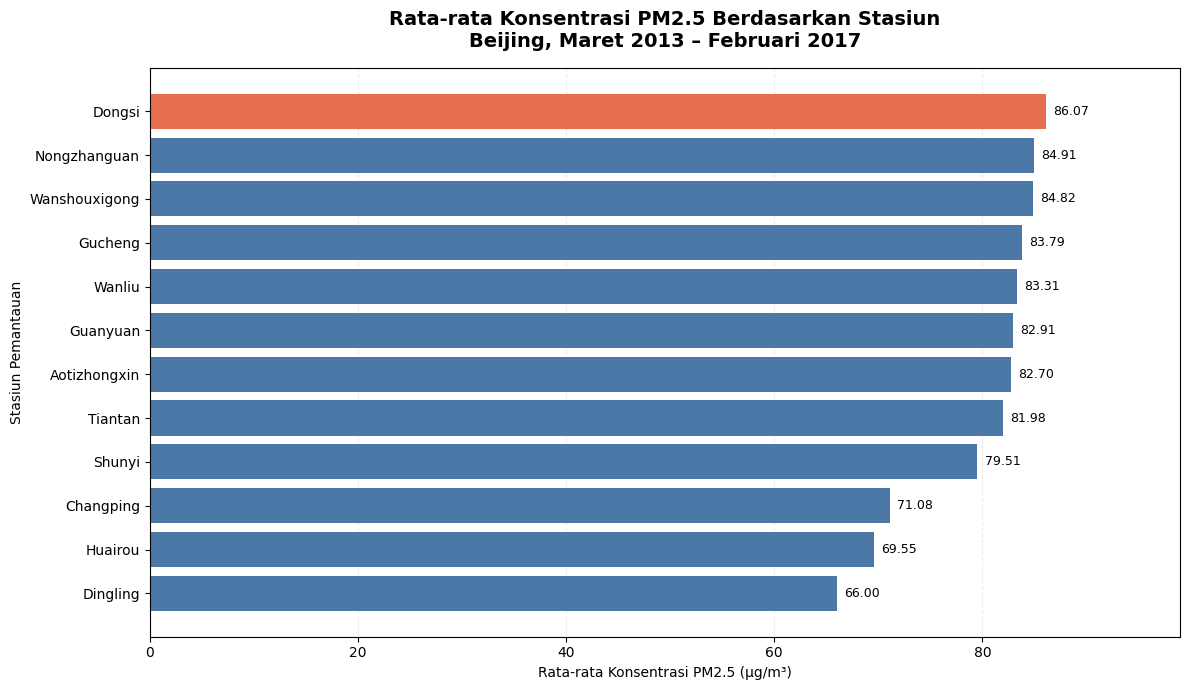

In [31]:

# Menyiapkan data visualisasi
station_plot = pm25_per_station.sort_values(
    by="Rata-rata PM2.5",
    ascending=True
)

# Menentukan warna batang
colors = [
    "#E76F51" if station == "Dongsi" else "#4C78A8"
    for station in station_plot.index
]

# Membuat horizontal bar chart
plt.figure(figsize=(12, 7))

bars = plt.barh(
    station_plot.index,
    station_plot["Rata-rata PM2.5"],
    color=colors
)

# Menambahkan label nilai pada batang
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        fontsize=9
    )

# Menambahkan judul dan label
plt.title(
    "Rata-rata Konsentrasi PM2.5 Berdasarkan Stasiun\n"
    "Beijing, Maret 2013 – Februari 2017",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Rata-rata Konsentrasi PM2.5 (µg/m³)")
plt.ylabel("Stasiun Pemantauan")

# Mengatur batas sumbu dan tampilan
plt.xlim(0, station_plot["Rata-rata PM2.5"].max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()


### Pertanyaan 2: Pola Rata-rata Konsentrasi PM2.5 Berdasarkan Bulan

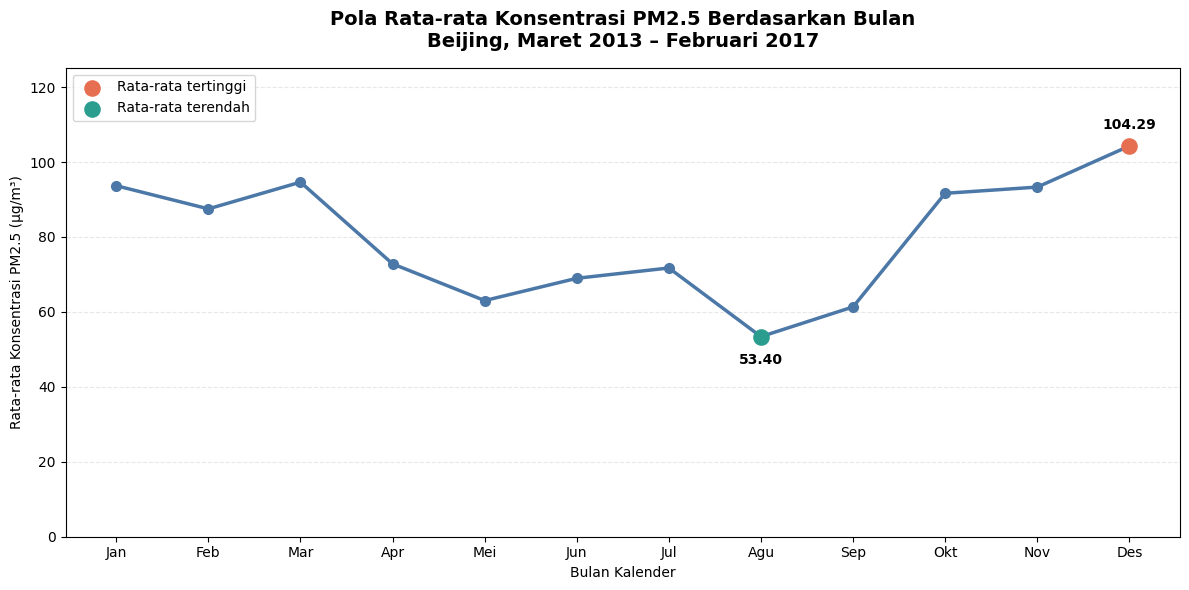

In [32]:

# Menyiapkan data rata-rata PM2.5 per bulan
bulan = [
    "Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
    "Jul", "Agu", "Sep", "Okt", "Nov", "Des"
]

rata_rata_pm25 = pm25_per_month["Rata-rata PM2.5"].values

# Membuat line chart
plt.figure(figsize=(12, 6))

plt.plot(
    bulan,
    rata_rata_pm25,
    marker="o",
    markersize=7,
    linewidth=2.5,
    color="#4C78A8"
)

# Menandai bulan dengan rata-rata tertinggi
index_tertinggi = rata_rata_pm25.argmax()
index_terendah = rata_rata_pm25.argmin()

plt.scatter(
    bulan[index_tertinggi],
    rata_rata_pm25[index_tertinggi],
    color="#E76F51",
    s=120,
    zorder=5,
    label="Rata-rata tertinggi"
)

plt.scatter(
    bulan[index_terendah],
    rata_rata_pm25[index_terendah],
    color="#2A9D8F",
    s=120,
    zorder=5,
    label="Rata-rata terendah"
)

# Menambahkan label nilai tertinggi dan terendah
plt.annotate(
    f"{rata_rata_pm25[index_tertinggi]:.2f}",
    (bulan[index_tertinggi], rata_rata_pm25[index_tertinggi]),
    xytext=(0, 12),
    textcoords="offset points",
    ha="center",
    fontweight="bold"
)

plt.annotate(
    f"{rata_rata_pm25[index_terendah]:.2f}",
    (bulan[index_terendah], rata_rata_pm25[index_terendah]),
    xytext=(0, -20),
    textcoords="offset points",
    ha="center",
    fontweight="bold"
)

# Judul dan keterangan grafik
plt.title(
    "Pola Rata-rata Konsentrasi PM2.5 Berdasarkan Bulan\n"
    "Beijing, Maret 2013 – Februari 2017",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Bulan Kalender")
plt.ylabel("Rata-rata Konsentrasi PM2.5 (µg/m³)")

# Mengatur tampilan
plt.ylim(0, rata_rata_pm25.max() * 1.2)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


**Insight:**
- Visualisasi Pertanyaan 1: Grafik batang horizontal menunjukkan bahwa stasiun Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 86,07 µg/m³, sedangkan Dingling memiliki rata-rata terendah sebesar 66,00 µg/m³. Selisih sebesar 20,07 µg/m³ menunjukkan adanya variasi konsentrasi PM2.5 antarlokasi pemantauan selama periode Maret 2013 hingga Februari 2017.
- Visualisasi Pertanyaan 2: Grafik garis menunjukkan bahwa Desember memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 104,29 µg/m³, sedangkan Agustus memiliki rata-rata terendah sebesar 53,40 µg/m³. Selisih sebesar 50,89 µg/m³ menunjukkan adanya variasi konsentrasi PM2.5 berdasarkan bulan kalender. Grafik ini menggabungkan data pada bulan kalender yang sama dari beberapa tahun selama periode pengamatan, sehingga tidak menggambarkan perubahan secara kronologis dari tahun 2013 hingga 2017.
- Interpretasi keseluruhan: Kedua visualisasi menunjukkan bahwa konsentrasi PM2.5 memiliki variasi berdasarkan lokasi dan bulan pengamatan. Temuan ini dapat menjadi bahan pertimbangan dalam menentukan prioritas evaluasi dan pemantauan kualitas udara pada lokasi serta periode dengan konsentrasi rata-rata yang lebih tinggi.
- Keterbatasan analisis: Hasil visualisasi menggunakan data pengukuran yang tersedia dan hasil interpolasi terbatas. Nilai yang masih kosong tidak disertakan dalam perhitungan rata-rata. Selain itu, hasil analisis bersifat deskriptif sehingga tidak dapat digunakan untuk memastikan hubungan sebab-akibat maupun menjelaskan faktor penyebab perbedaan konsentrasi PM2.5.

## Analisis Lanjutan: Binning Konsentrasi PM2.5

Teknik analisis lanjutan yang digunakan adalah **binning**, yaitu pengelompokan nilai numerik ke dalam beberapa interval menggunakan fungsi `pd.cut()`.

Tujuan analisis ini adalah mengidentifikasi distribusi konsentrasi PM2.5 berdasarkan kategori interval serta membandingkan proporsi pengukuran dengan konsentrasi tinggi pada setiap stasiun pemantauan.

Kategori yang digunakan merupakan kategori analitis khusus untuk eksplorasi dataset, bukan klasifikasi resmi indeks kualitas udara. Analisis ini tidak menggunakan algoritma machine learning.

In [33]:

# Membuat kategori konsentrasi PM2.5 menggunakan binning
bins = [0, 25, 50, 100, 150, np.inf]

labels = [
    "Sangat Rendah",
    "Rendah",
    "Sedang",
    "Tinggi",
    "Sangat Tinggi"
]

# Mengelompokkan data berdasarkan interval PM2.5
air_quality_clean_df["Kategori_PM25"] = pd.cut(
    air_quality_clean_df["PM2.5"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Menghitung jumlah data di setiap kategori
kategori_count = (
    air_quality_clean_df["Kategori_PM25"]
    .value_counts()
    .sort_index()
)

print("=== DISTRIBUSI KATEGORI PM2.5 ===")
print(kategori_count)

# Menghitung persentase setiap kategori
kategori_percentage = (
    air_quality_clean_df["Kategori_PM25"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\n=== PERSENTASE KATEGORI PM2.5 ===")
print(kategori_percentage.round(2))

# Menghitung proporsi kategori tinggi dan sangat tinggi
proporsi_tinggi = (
    air_quality_clean_df
    .assign(
        PM25_Tinggi=lambda df: df["PM2.5"] > 100
    )
    .groupby("station")
    .apply(
        lambda df: (
            df["PM25_Tinggi"].sum() /
            df["PM2.5"].count() * 100
        ),
        include_groups=False
    )
    .sort_values(ascending=False)
)

print("\n=== PROPORSI PM2.5 > 100 PER STASIUN ===")
print(proporsi_tinggi.round(2))


=== DISTRIBUSI KATEGORI PM2.5 ===
Kategori_PM25
Sangat Rendah    123490
Rendah            73180
Sedang           100731
Tinggi            54986
Sangat Tinggi     63096
Name: count, dtype: int64

=== PERSENTASE KATEGORI PM2.5 ===
Kategori_PM25
Sangat Rendah    29.72
Rendah           17.61
Sedang           24.24
Tinggi           13.23
Sangat Tinggi    15.19
Name: proportion, dtype: float64

=== PROPORSI PM2.5 > 100 PER STASIUN ===
station
Dongsi           31.12
Wanshouxigong    30.38
Gucheng          30.27
Wanliu           30.12
Nongzhanguan     30.04
Guanyuan         29.88
Aotizhongxin     29.61
Tiantan          29.33
Shunyi           28.61
Changping        24.83
Huairou          24.14
Dingling         22.64
dtype: float64


**Insight:**
- Analisis lanjutan dilakukan menggunakan teknik binning melalui fungsi pd.cut() untuk mengelompokkan konsentrasi PM2.5 ke dalam lima interval analitis, yaitu Sangat Rendah (0–25 µg/m³), Rendah (>25–50 µg/m³), Sedang (>50–100 µg/m³), Tinggi (>100–150 µg/m³), dan Sangat Tinggi (>150 µg/m³). Pengelompokan ini bertujuan untuk memahami distribusi konsentrasi PM2.5 dan bukan merupakan klasifikasi resmi kualitas udara seperti ISPU.
- Berdasarkan hasil binning, kategori Sangat Rendah memiliki jumlah pengukuran terbanyak, yaitu 123.490 data (29,72%). Sementara itu, kategori Tinggi dan Sangat Tinggi, yang mewakili konsentrasi PM2.5 di atas 100 µg/m³, mencakup sekitar 28,42% dari seluruh pengukuran valid.
- Berdasarkan perbandingan antarstasiun, Dongsi memiliki proporsi pengukuran PM2.5 di atas 100 µg/m³ tertinggi, yaitu 31,12%, sedangkan Dingling memiliki proporsi terendah sebesar 22,64%. Temuan ini sejalan dengan hasil EDA sebelumnya yang menunjukkan bahwa Dongsi memiliki rata-rata PM2.5 tertinggi dan Dingling memiliki rata-rata terendah.
- Analisis binning memberikan informasi tambahan mengenai distribusi dan frekuensi pengukuran pada setiap interval konsentrasi PM2.5 yang tidak sepenuhnya tergambarkan melalui nilai rata-rata. Hasil ini dapat digunakan sebagai bahan pertimbangan dalam menentukan prioritas evaluasi kualitas udara berdasarkan lokasi pemantauan.
- Analisis menggunakan nilai PM2.5 yang tersedia, termasuk hasil interpolasi terbatas. Pengukuran yang masih kosong tidak dimasukkan dalam perhitungan frekuensi maupun proporsi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan analisis rata-rata konsentrasi PM2.5 pada 12 stasiun pemantauan kualitas udara di Beijing selama periode 1 Maret 2013 hingga 28 Februari 2017, stasiun Dongsi memiliki rata-rata konsentrasi tertinggi sebesar 86,07 µg/m³, sedangkan Dingling memiliki rata-rata terendah sebesar 66,00 µg/m³. Selisih sebesar 20,07 µg/m³ menunjukkan adanya variasi konsentrasi PM2.5 antarlokasi. Analisis lanjutan juga menunjukkan bahwa Dongsi memiliki proporsi pengukuran PM2.5 di atas 100 µg/m³ tertinggi, yaitu 31,12%. Oleh karena itu, stasiun Dongsi dapat menjadi salah satu prioritas evaluasi kualitas udara berdasarkan hasil pengamatan historis.
- **Conclusion pertanyaan 2:** Berdasarkan analisis rata-rata konsentrasi PM2.5 menurut bulan kalender selama periode pengamatan, Desember memiliki rata-rata tertinggi sebesar 104,29 µg/m³, sedangkan Agustus memiliki rata-rata terendah sebesar 53,40 µg/m³. Selisih sebesar 50,89 µg/m³ menunjukkan adanya variasi konsentrasi PM2.5 antarbulan. Analisis ini menggabungkan pengamatan pada bulan kalender yang sama dari beberapa tahun, sehingga hasilnya menggambarkan pola rata-rata bulanan, bukan tren kronologis. Temuan tersebut dapat menjadi pertimbangan dalam meningkatkan perhatian terhadap pemantauan kualitas udara pada periode sekitar akhir tahun.

**Rekomendasi Action Item:**
- Memprioritaskan evaluasi kualitas udara di stasiun Dongsi. Berdasarkan rata-rata konsentrasi PM2.5 dan proporsi pengukuran di atas 100 µg/m³ yang tertinggi, pengelola pemantauan kualitas udara disarankan meningkatkan perhatian terhadap lokasi Dongsi, termasuk mengevaluasi kondisi lingkungan dan kemungkinan sumber emisi melalui pengumpulan data tambahan.
- Meningkatkan kesiapan pemantauan menjelang dan selama Desember. Berdasarkan pola historis yang menunjukkan bahwa Desember memiliki rata-rata PM2.5 tertinggi, pihak terkait dapat mempertimbangkan pemantauan lebih intensif pada periode tersebut serta menyiapkan komunikasi informasi kualitas udara kepada masyarakat berdasarkan hasil pengukuran terkini.
- Melakukan analisis lanjutan untuk mengidentifikasi faktor yang berkaitan dengan variasi PM2.5. Penelitian berikutnya dapat mempertimbangkan variabel meteorologi, aktivitas transportasi, dan sumber emisi untuk memahami faktor yang mungkin berhubungan dengan perbedaan konsentrasi PM2.5 antarstasiun dan antarbulan. Hal ini diperlukan karena analisis saat ini belum membuktikan hubungan sebab-akibat.
- Meningkatkan kelengkapan pengukuran pada seluruh stasiun. Mengingat masih terdapat 5.285 nilai PM2.5 yang kosong setelah interpolasi terbatas, pengelola data disarankan mengevaluasi kontinuitas pencatatan dan kualitas perangkat pengukuran untuk mengurangi missing value pada periode pemantauan berikutnya.

### Pengolahan data untuk Streamlit

In [34]:

import os

# Menentukan lokasi penyimpanan hasil analisis
if os.path.isdir("dashboard"):
    file_path = "dashboard/main_data.csv"
else:
    file_path = "/content/main_data.csv"

# Menyimpan dataset hasil cleaning
air_quality_clean_df.to_csv(
    file_path,
    index=False
)

# Memastikan file berhasil disimpan
print("=== HASIL EKSPOR DATA ===")
print("Lokasi file:", file_path)
print("File berhasil dibuat:", os.path.exists(file_path))
print(
    "Ukuran file (MB):",
    round(os.path.getsize(file_path) / (1024 * 1024), 2)
)
print("Ukuran DataFrame:", air_quality_clean_df.shape)


=== HASIL EKSPOR DATA ===
Lokasi file: /content/main_data.csv
File berhasil dibuat: True
Ukuran file (MB): 38.73
Ukuran DataFrame: (420768, 19)
